# Q3 - Initial ANN (ResNet18/34, frozen backbone)

Results for `scripts/train_ann.py`'s 12-config hyperparameter search over learning rate,
batch size, and backbone depth (resnet18 vs resnet34) - backbone frozen throughout, only the
head trains. The script does the training (on GPU; a frozen-backbone CPU run is impractically
slow) and logs every config to `experiments/log.csv`; this notebook loads the saved model and
history to build the figures/analysis - no training happens here, keeping with `notebooks/`
being for analysis, not duplicated pipeline logic.

**Test isolation:** everything below uses validation data only, same as `train_ann.py` - test
is never read here either.

**Note on the baseline comparison:** `notebooks/02_baseline.ipynb` already loaded the
LightGBM model and computed its recall at `P_MIN=0.30` (0.850, from that notebook's own PR
curve cell) - that number is referenced below rather than recomputed here. Loading a LightGBM
model and running any torch op in the same process is unreliable on this machine (sometimes a
segfault, sometimes a hang - both libraries bundle their own OpenMP runtime and the two don't
coexist safely), so this notebook never imports `joblib`/`lightgbm` at all; the rest of the
baseline's numbers come from `experiments/log.csv`, which is plain text.

In [3]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"
P_MIN = 0.30  # official primary metric threshold - see docs/primary_metric.md

splits = pd.read_csv(DATA_DIR / "splits.csv")
val_df = splits[splits["split"] == "val"].reset_index(drop=True)

# From notebooks/02_baseline.ipynb's PR-curve cell (P_MIN=0.30 marker) - not recomputed here,
# see the note above.
baseline_recall_at_p_min = 0.850

log = pd.read_csv(PROJECT_ROOT / "experiments" / "log.csv")
baseline_runs = log[log["model"] == "LightGBM (HOG+LBP)"].reset_index(drop=True)
baseline_metrics = baseline_runs["validation_metrics"].apply(json.loads)
baseline_best_idx = baseline_metrics.apply(lambda m: m["crystals_pr_auc"]).idxmax()
baseline_best_metrics = baseline_metrics[baseline_best_idx]

print(f"baseline: {baseline_runs.loc[baseline_best_idx, 'id']}, recall@P_MIN={baseline_recall_at_p_min:.3f}")

baseline: baseline_lgbm_022, recall@P_MIN=0.850


## Setup

In [4]:
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import confusion_matrix, precision_recall_curve
from torch.utils.data import DataLoader

from marco.data import CLASS_ORDER, MarcoDataset
from marco.model import build_model

FIGURES_DIR = PROJECT_ROOT / "docs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

CLASS_COLORS = {
    "Clear": "#0072B2",
    "Crystals": "#D55E00",
    "Precipitate": "#E69F00",
    "Other": "#999999",
}

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["figure.dpi"] = 100

In [5]:
ckpt = json.load(open(PROJECT_ROOT / "experiments" / "models" / "ann_initial_history.json"))
params = ckpt["params"]
history = ckpt["history"]

model = build_model(params["backbone"])
model.load_state_dict(torch.load(PROJECT_ROOT / "experiments" / "models" / "ann_initial.pt", map_location="cpu"))
model.eval()

ann_runs = log[log["model"].str.startswith("ANN Initial")].reset_index(drop=True)
ann_metrics = ann_runs["validation_metrics"].apply(json.loads)
ann_runs["recall_at_p_min"] = ann_metrics.apply(lambda m: m["recall_at_p_min"])
ann_runs["crystals_pr_auc"] = ann_metrics.apply(lambda m: m["crystals_pr_auc"])
ann_runs["train_time_s"] = ann_metrics.apply(lambda m: m["train_time_s"])
ann_runs["inference_latency_ms_per_image"] = ann_metrics.apply(lambda m: m["inference_latency_ms_per_image"])
ann_runs["hyperparameters"] = ann_runs["hyperparameters"].apply(json.loads)

print(f"best config: {params}")
print(f"trained on {len(ann_runs)} configs, logged as {ann_runs['id'].tolist()}")

best config: {'backbone': 'resnet18', 'learning_rate': 0.001, 'batch_size': 16}
trained on 12 configs, logged as ['ann_initial_000', 'ann_initial_001', 'ann_initial_002', 'ann_initial_003', 'ann_initial_004', 'ann_initial_005', 'ann_initial_006', 'ann_initial_007', 'ann_initial_008', 'ann_initial_009', 'ann_initial_010', 'ann_initial_011']


## Hyperparameter search (12 configs)

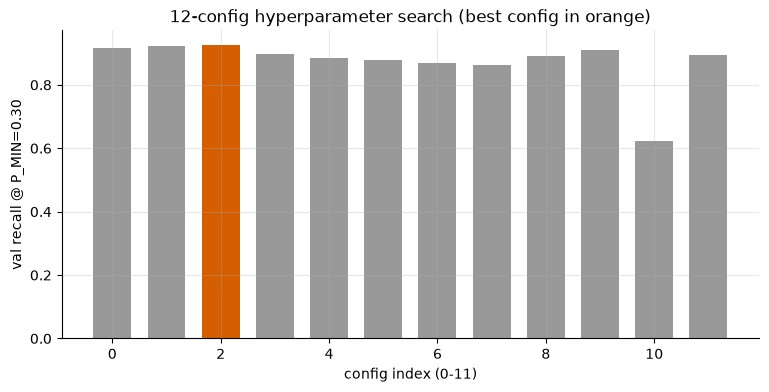

best: ann_initial_002, {'backbone': 'resnet18', 'learning_rate': 0.001, 'batch_size': 16}
recall@P_MIN=0.925, crystals_pr_auc=0.572, train_time=1060.0s
search range (recall@P_MIN): 0.622 - 0.925


,id,hyperparameters,recall_at_p_min,crystals_pr_auc,train_time_s
0,ann_initial_000,"{'backbone': 'resnet18', 'learning_rate': 0.00...",0.917323,0.569072,1115.44
1,ann_initial_001,"{'backbone': 'resnet18', 'learning_rate': 0.00...",0.921260,0.593306,1095.17
2,ann_initial_002,"{'backbone': 'resnet18', 'learning_rate': 0.00...",0.925197,0.571800,1060.03
3,ann_initial_003,"{'backbone': 'resnet18', 'learning_rate': 0.00...",0.897638,0.547816,1097.50
4,ann_initial_004,"{'backbone': 'resnet34', 'learning_rate': 0.00...",0.885827,0.559456,1071.20
5,ann_initial_005,"{'backbone': 'resnet34', 'learning_rate': 0.00...",0.877953,0.564587,1043.39
6,ann_initial_006,"{'backbone': 'resnet34', 'learning_rate': 0.00...",0.870079,0.559661,1046.45
7,ann_initial_007,"{'backbone': 'resnet18', 'learning_rate': 0.01...",0.862205,0.566252,1075.55
8,ann_initial_008,"{'backbone': 'resnet34', 'learning_rate': 0.00...",0.889764,0.559622,1049.34
9,ann_initial_009,"{'backbone': 'resnet34', 'learning_rate': 0.00...",0.909449,0.550977,1103.56


In [6]:
best_idx = ann_runs["recall_at_p_min"].idxmax()
colors = ["#D55E00" if i == best_idx else "#999999" for i in range(len(ann_runs))]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(len(ann_runs)), ann_runs["recall_at_p_min"], color=colors, width=0.7)
ax.set_xlabel("config index (0-11)")
ax.set_ylabel("val recall @ P_MIN=0.30")
ax.set_title("12-config hyperparameter search (best config in orange)")
fig.savefig(FIGURES_DIR / "q3_ann_initial_search.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"best: {ann_runs.loc[best_idx, 'id']}, {ann_runs.loc[best_idx, 'hyperparameters']}")
print(f"recall@P_MIN={ann_runs.loc[best_idx, 'recall_at_p_min']:.3f}, "
      f"crystals_pr_auc={ann_runs.loc[best_idx, 'crystals_pr_auc']:.3f}, "
      f"train_time={ann_runs.loc[best_idx, 'train_time_s']:.1f}s")
print(f"search range (recall@P_MIN): {ann_runs['recall_at_p_min'].min():.3f} - "
      f"{ann_runs['recall_at_p_min'].max():.3f}")
ann_runs[["id", "hyperparameters", "recall_at_p_min", "crystals_pr_auc", "train_time_s"]]

**Reading this:** config 10 (`learning_rate=0.01`, `batch_size=16`) collapsed - a high learning
rate paired with a small batch size destabilised training (loss diverged to 2.85 instead of
falling). That failure, alongside the 11 configs that trained normally, is logged in
`experiments/log.csv` exactly as it happened - nothing is hidden or re-run away.

## Learning curves (best config) - under/overfitting diagnosis

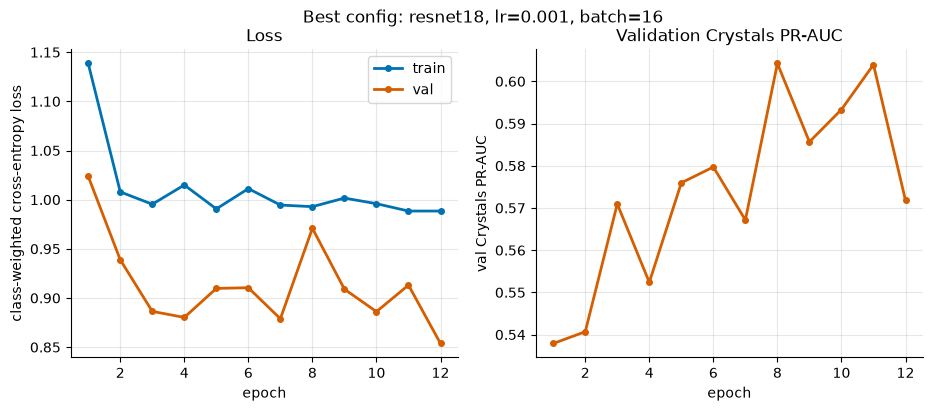

In [5]:
epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs, history["train_loss"], color="#0072B2", lw=2, marker="o", ms=4, label="train")
axes[0].plot(epochs, history["val_loss"], color="#D55E00", lw=2, marker="o", ms=4, label="val")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("class-weighted cross-entropy loss")
axes[0].set_title("Loss"); axes[0].legend()

axes[1].plot(epochs, history["val_crystals_pr_auc"], color="#D55E00", lw=2, marker="o", ms=4)
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("val Crystals PR-AUC")
axes[1].set_title("Validation Crystals PR-AUC")

fig.suptitle(f"Best config: {params['backbone']}, lr={params['learning_rate']}, batch={params['batch_size']}")
fig.savefig(FIGURES_DIR / "q3_ann_initial_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading this:** both losses drop in epoch 1 and then plateau - train loss sits around
0.99-1.01 and val loss fluctuates around 0.85-0.97 for the remaining 11 epochs, with neither
curve trending away from the other. That rules out classic overfitting (val loss would climb
while train loss kept falling) but it also means the head stops improving almost immediately:
with the backbone frozen, only a Dropout+Linear head is learning, and that is not enough
capacity to keep extracting more signal from the fixed ImageNet features. Val loss sitting
*below* train loss for most epochs is expected, not a bug - `Dropout(0.4)` is active during
training and switched off for evaluation, so the training loss is measured under more noise.
This plateau is the direct motivation for the Final ANN (partial unfreeze), once approved -
the frozen head alone has already converged to its ceiling.

## Running the model on the validation set

In [6]:
val_loader = DataLoader(MarcoDataset(val_df, DATA_DIR, train=False), batch_size=32, shuffle=False, num_workers=0)

all_probs, all_labels = [], []
with torch.no_grad():
    for imgs, labels in val_loader:
        all_probs.append(torch.softmax(model(imgs), dim=1).numpy())
        all_labels.append(labels.numpy())
all_probs = np.concatenate(all_probs)
all_labels = np.concatenate(all_labels)

y_val = np.array(CLASS_ORDER)[all_labels]
preds = np.array(CLASS_ORDER)[all_probs.argmax(axis=1)]
print(f"inference on {len(y_val)} val images done")

inference on 2053 val images done


## Confusion matrix (default argmax threshold)

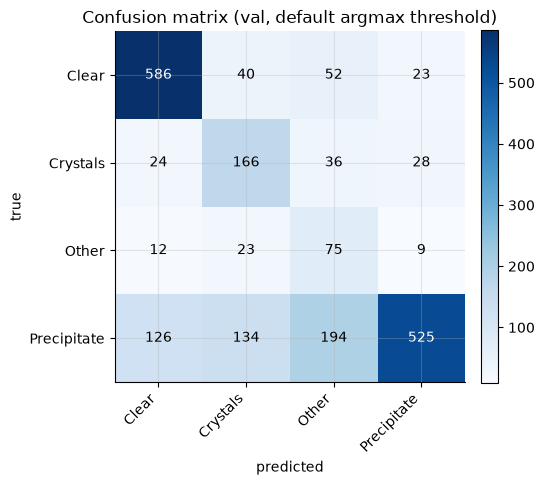

,Clear,Crystals,Other,Precipitate
Clear,586,40,52,23
Crystals,24,166,36,28
Other,12,23,75,9
Precipitate,126,134,194,525


In [7]:
cm = confusion_matrix(y_val, preds, labels=CLASS_ORDER)

fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(4)); ax.set_xticklabels(CLASS_ORDER, rotation=45, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels(CLASS_ORDER)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Confusion matrix (val, default argmax threshold)")
for i in range(4):
    for j in range(4):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color=color, fontsize=10)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "q3_ann_initial_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame(cm, index=CLASS_ORDER, columns=CLASS_ORDER)

## PR curve for Crystals, with P_MIN=0.30 and 0.25 marked

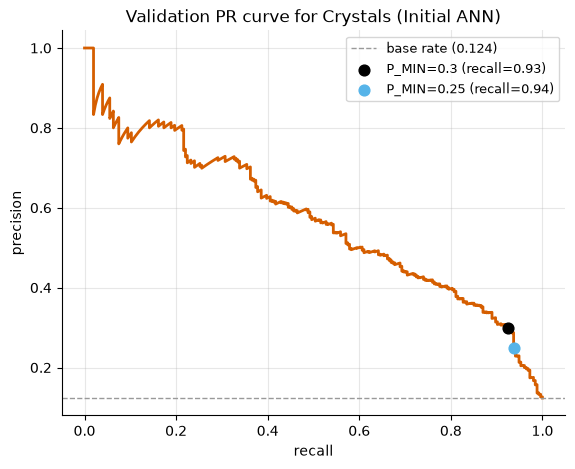

In [8]:
crystals_idx = CLASS_ORDER.index("Crystals")
y_bin = (all_labels == crystals_idx).astype(int)
crystals_scores = all_probs[:, crystals_idx]
precision, recall, thresholds = precision_recall_curve(y_bin, crystals_scores)

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(recall, precision, color=CLASS_COLORS["Crystals"], lw=2)
ax.axhline(y_bin.mean(), color="#999999", ls="--", lw=1, label=f"base rate ({y_bin.mean():.3f})")

for target_p, marker_color in [(0.30, "#000000"), (0.25, "#56B4E9")]:
    diffs = np.abs(precision[:-1] - target_p)
    idx = np.argmin(diffs)
    ax.scatter(recall[idx], precision[idx], color=marker_color, zorder=5, s=60,
               label=f"P_MIN={target_p} (recall={recall[idx]:.2f})")

ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.set_title("Validation PR curve for Crystals (Initial ANN)")
ax.legend(loc="upper right", fontsize=9)
fig.savefig(FIGURES_DIR / "q3_ann_initial_pr_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## Comparison with the classical baseline

The trivial benchmark and Final ANN rows are not in this table yet - the Final ANN is pending
the lecturer's degree-of-fine-tuning approval (see `docs/`).

In [9]:
comparison = pd.DataFrame([
    {
        "model": "Classical baseline (LightGBM, HOG+LBP)",
        "recall_at_p_min": round(baseline_recall_at_p_min, 3),
        "crystals_pr_auc": round(baseline_best_metrics["crystals_pr_auc"], 3),
        "train_time_s": baseline_best_metrics["train_time_s"],
        "inference_latency_ms_per_image": baseline_best_metrics["inference_latency_ms_per_image"],
    },
    {
        "model": f"Initial ANN ({params['backbone']}, frozen backbone)",
        "recall_at_p_min": round(ann_runs.loc[best_idx, "recall_at_p_min"], 3),
        "crystals_pr_auc": round(ann_runs.loc[best_idx, "crystals_pr_auc"], 3),
        "train_time_s": round(ann_runs.loc[best_idx, "train_time_s"], 1),
        "inference_latency_ms_per_image": round(ann_runs.loc[best_idx, "inference_latency_ms_per_image"], 4),
    },
])
comparison

,model,recall_at_p_min,crystals_pr_auc,train_time_s,inference_latency_ms_per_image
0,"Classical baseline (LightGBM, HOG+LBP)",0.850,0.652,28.85,0.0300
1,"Initial ANN (resnet18, frozen backbone)",0.925,0.572,1060.00,6.3358


**Reading this:** the Initial ANN already reaches a notably higher recall at the fixed
`P_MIN=0.30` than the classical baseline, at the cost of a much longer training time and
slower per-image inference (ms instead of microseconds) - expected for a CNN forward pass
versus a handful of gradient-boosted trees on hand-crafted features. Both inference-latency
figures above were measured on different hardware (baseline: this laptop's CPU; ANN: the GPU
it trained on), so the absolute gap is not a fair like-for-like comparison yet - that still
needs to be measured consistently for the final report table.